Libraries imported successfully!

Dataset:


,Area,Bedrooms,Bathrooms,Age,Price
0,1000,2,1,10,25
1,1200,2,1,8,30
2,1500,3,2,5,40
3,1800,3,2,7,45
4,2000,3,2,4,50
5,2200,4,2,6,55
6,2500,4,3,3,65
7,2800,4,3,5,70
8,3000,4,3,2,75
9,3200,5,3,4,85



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Area       20 non-null     int64
 1   Bedrooms   20 non-null     int64
 2   Bathrooms  20 non-null     int64
 3   Age        20 non-null     int64
 4   Price      20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes

Statistical Description:


,Area,Bedrooms,Bathrooms,Age,Price
count,20.000000,20.000000,20.000000,20.000000,20.000000
mean,3450.000000,4.800000,3.450000,3.600000,96.500000
std,1608.693488,1.735087,1.538112,2.542274,51.786505
min,1000.000000,2.000000,1.000000,1.000000,25.000000
25%,2150.000000,3.750000,2.000000,2.000000,53.750000
50%,3350.000000,5.000000,3.000000,3.000000,87.500000
75%,4575.000000,6.000000,5.000000,5.000000,136.250000
max,6500.000000,8.000000,6.000000,10.000000,200.000000



Missing Values:
Area         0
Bedrooms     0
Bathrooms    0
Age          0
Price        0
dtype: int64


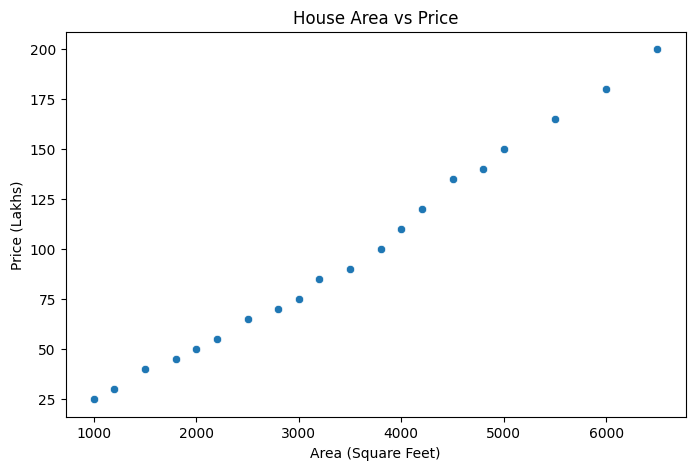

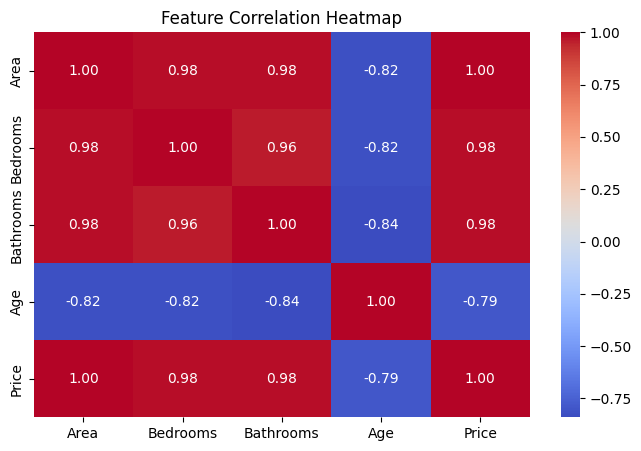

Training samples: 16
Testing samples: 4

Linear Regression
MAE: 6.66
MSE: 53.83
RMSE: 7.34
R2 Score: 0.9865

Ridge Regression
MAE: 5.29
MSE: 35.26
RMSE: 5.94
R2 Score: 0.9912

Random Forest
MAE: 12.16
MSE: 166.91
RMSE: 12.92
R2 Score: 0.9581

MODEL PERFORMANCE COMPARISON:


,MAE,MSE,RMSE,R2 Score
Linear Regression,6.656787,53.826293,7.336640,0.986501
Ridge Regression,5.291654,35.256922,5.937754,0.991158
Random Forest,12.162500,166.914375,12.919535,0.958141


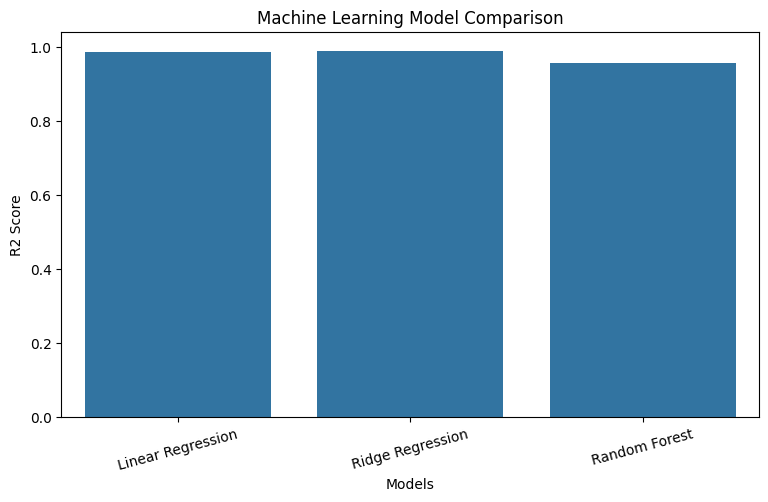


HOUSE PRICE PREDICTION
Area: 2000 Square Feet
Bedrooms: 3
Bathrooms: 2
Age: 3 Years

Predicted House Price: 42.64 Lakhs


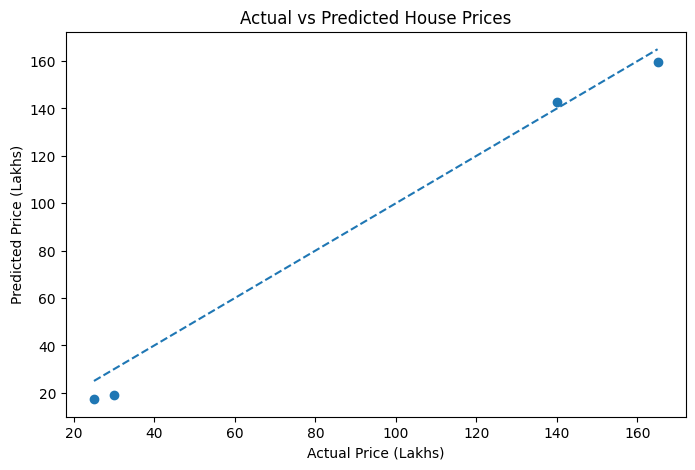


PROJECT COMPLETED SUCCESSFULLY!


In [1]:

# ==========================================================
# HOUSE PRICE PREDICTION USING MACHINE LEARNING
# Algorithms: Linear Regression, Ridge, Random Forest
# Platform: Anaconda Jupyter Notebook
# ==========================================================

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


# 2. CREATE DATASET

data = {
    'Area': [1000, 1200, 1500, 1800, 2000, 2200,
             2500, 2800, 3000, 3200, 3500, 3800,
             4000, 4200, 4500, 4800, 5000, 5500,
             6000, 6500],

    'Bedrooms': [2, 2, 3, 3, 3, 4, 4, 4, 4, 5,
                 5, 5, 5, 6, 6, 6, 7, 7, 7, 8],

    'Bathrooms': [1, 1, 2, 2, 2, 2, 3, 3, 3, 3,
                  3, 4, 4, 4, 5, 5, 5, 5, 6, 6],

    'Age': [10, 8, 5, 7, 4, 6, 3, 5, 2, 4,
            3, 2, 1, 2, 1, 3, 2, 1, 2, 1],

    'Price': [25, 30, 40, 45, 50, 55, 65, 70,
              75, 85, 90, 100, 110, 120, 135,
              140, 150, 165, 180, 200]
}

df = pd.DataFrame(data)

print("\nDataset:")
display(df.head(10))


# 3. EXPLORE DATASET

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


# 4. DATA VISUALIZATION

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Area', y='Price')

plt.title("House Area vs Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Price (Lakhs)")
plt.show()


# 5. CORRELATION HEATMAP

plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()


# 6. FEATURE SELECTION

X = df[['Area', 'Bedrooms', 'Bathrooms', 'Age']]

y = df['Price']


# 7. SPLIT DATASET INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# 8. TRAIN MACHINE LEARNING MODELS

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = {}

trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Evaluate model
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

    trained_models[name] = model

    print("\n================================")
    print(name)
    print("================================")

    print("MAE:", round(mae, 2))
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))


# 9. MODEL COMPARISON

results_df = pd.DataFrame(results).T

print("\nMODEL PERFORMANCE COMPARISON:")

display(results_df)


# 10. VISUALIZE MODEL PERFORMANCE

plt.figure(figsize=(9, 5))

sns.barplot(
    x=results_df.index,
    y=results_df['R2 Score']
)

plt.title("Machine Learning Model Comparison")

plt.xlabel("Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)

plt.show()


# 11. PREDICT NEW HOUSE PRICE

new_house = pd.DataFrame({
    'Area': [2000],
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Age': [3]
})

model = trained_models["Linear Regression"]

predicted_price = model.predict(new_house)[0]

print("\n================================")
print("HOUSE PRICE PREDICTION")
print("================================")

print("Area: 2000 Square Feet")
print("Bedrooms: 3")
print("Bathrooms: 2")
print("Age: 3 Years")

print("\nPredicted House Price:",
      round(predicted_price, 2), "Lakhs")


# 12. ACTUAL VS PREDICTED PRICE

predictions = model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")

plt.title("Actual vs Predicted House Prices")

plt.show()


print("\nPROJECT COMPLETED SUCCESSFULLY!")
